In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

# Зареждане
df = pd.read_csv(
    "data/traffic_aggregated.csv",
    parse_dates=["datetime"]
)

# Feature Engineering
df["hour"]          = df["datetime"].dt.hour
df["dow"]           = df["datetime"].dt.dayofweek
df["month"]         = df["datetime"].dt.month
df["direction_enc"] = (df["direction"] == "Център").astype(int)
df["hour_sin"]      = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"]      = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]       = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"]       = np.cos(2 * np.pi * df["dow"] / 7)
df["month_sin"]     = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"]     = np.cos(2 * np.pi * df["month"] / 12)

feature_cols = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
                "month_sin", "month_cos", "direction_enc"]

print(f"Редове       : {len(df):,}")
print(f"Null volume  : {df['volume'].isnull().sum():,} ({df['volume'].isnull().mean()*100:.1f}%)")
print(f"Период       : {df['datetime'].min()} → {df['datetime'].max()}")

Устройство: cuda
Редове       : 52,608
Null volume  : 16,625 (31.6%)
Период       : 2022-01-01 00:00:00 → 2024-12-31 23:00:00


ВИЗУАЛИЗАЦИЯ НА ОРИГИНАЛНИЯ ВРЕМЕВИ РЕД


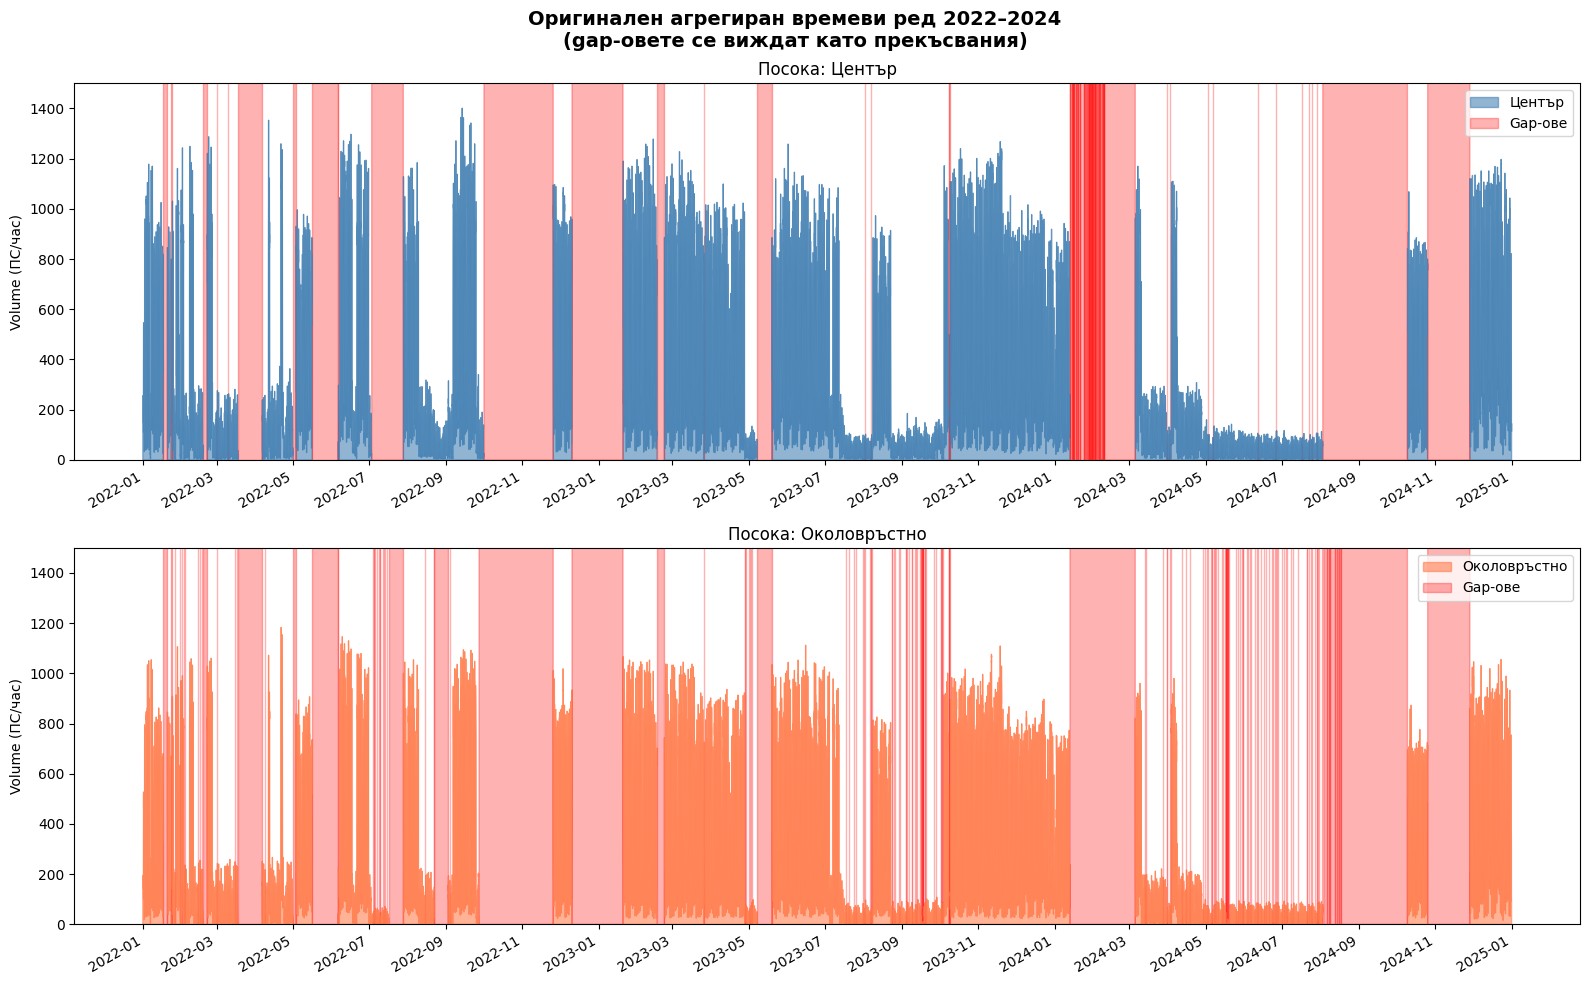


Статистика за gap-овете:
  Общо null часове    : 16,625
  % липсващи          : 31.6%
  Часове с данни      : 35,983


In [2]:
print("=" * 60)
print("ВИЗУАЛИЗАЦИЯ НА ОРИГИНАЛНИЯ ВРЕМЕВИ РЕД")
print("=" * 60)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Оригинален агрегиран времеви ред 2022–2024\n(gap-овете се виждат като прекъсвания)",
             fontsize=14, fontweight="bold")

for ax, direction, color in zip(axes, ["Център", "Околовръстно"], 
                                 ["steelblue", "coral"]):
    sub = df[df["direction"] == direction]
    ax.fill_between(sub["datetime"], sub["volume"], 
                    alpha=0.6, color=color, label=direction)
    ax.plot(sub["datetime"], sub["volume"], 
            color=color, linewidth=0.5, alpha=0.8)
    
    # Маркираме gap-овете
    null_mask = sub["volume"].isnull()
    if null_mask.any():
        ax.fill_between(sub["datetime"], 0, 1500,
                        where=null_mask,
                        alpha=0.3, color="red", 
                        transform=ax.get_xaxis_transform(),
                        label="Gap-ове")
    
    ax.set_title(f"Посока: {direction}")
    ax.set_ylabel("Volume (ПС/час)")
    ax.set_ylim(0, 1500)
    ax.legend(loc="upper right")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("original_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

# Статистика за gap-овете
print(f"\nСтатистика за gap-овете:")
print(f"  Общо null часове    : {df['volume'].isnull().sum():,}")
print(f"  % липсващи          : {df['volume'].isnull().mean()*100:.1f}%")
print(f"  Часове с данни      : {df['volume'].notna().sum():,}")

In [3]:
print("=" * 60)
print("ХИБРИДНА ИМПУТАЦИЯ: RF + GAN")
print("=" * 60)

# Идентифицираме gap-овете и тяхната продължителност
df_copy = df.copy()

# Намираме последователните gap-ове
null_mask = df_copy.groupby("direction")["volume"].transform(lambda x: x.isnull())

# Прагът — над 168 часа (1 седмица) използваме GAN
THRESHOLD_HOURS = 168

# Намираме gap-овете по посока
gap_info = []
for direction in ["Център", "Околовръстно"]:
    sub = df_copy[df_copy["direction"] == direction].copy()
    sub = sub.reset_index(drop=True)
    
    in_gap    = False
    gap_start = None
    gap_idx   = []
    
    for i, row in sub.iterrows():
        if pd.isnull(row["volume"]) and not in_gap:
            gap_start = i
            in_gap    = True
            gap_idx   = [i]
        elif pd.isnull(row["volume"]) and in_gap:
            gap_idx.append(i)
        elif not pd.isnull(row["volume"]) and in_gap:
            gap_info.append({
                "direction" : direction,
                "start_idx" : gap_start,
                "end_idx"   : i - 1,
                "hours"     : len(gap_idx),
                "method"    : "GAN" if len(gap_idx) > THRESHOLD_HOURS else "RF",
                "indices"   : gap_idx.copy()
            })
            in_gap = False
            gap_idx = []
    
    if in_gap:
        gap_info.append({
            "direction" : direction,
            "start_idx" : gap_start,
            "end_idx"   : gap_idx[-1],
            "hours"     : len(gap_idx),
            "method"    : "GAN" if len(gap_idx) > THRESHOLD_HOURS else "RF",
            "indices"   : gap_idx.copy()
        })

gap_df = pd.DataFrame([{k: v for k, v in g.items() if k != "indices"} 
                        for g in gap_info])
print(f"Общо gap-ове    : {len(gap_df):,}")
print(f"Gap-ове за RF   : {(gap_df['method']=='RF').sum():,}")
print(f"Gap-ове за GAN  : {(gap_df['method']=='GAN').sum():,}")
print(f"\nРазпределение по продължителност и метод:")
print(gap_df.groupby(["method", "direction"])["hours"]
      .agg(["count","sum","mean","max"])
      .round(1).to_string())

ХИБРИДНА ИМПУТАЦИЯ: RF + GAN
Общо gap-ове    : 272
Gap-ове за RF   : 253
Gap-ове за GAN  : 19

Разпределение по продължителност и метод:
                     count   sum   mean   max
method direction                             
GAN    Околовръстно     10  7533  753.3  1426
       Център            9  7198  799.8  1628
RF     Околовръстно    174   902    5.2   142
       Център           79   992   12.6   139


In [4]:
print("=" * 60)
print("ОБУЧЕНИЕ НА МОДЕЛИТЕ")
print("=" * 60)

# Тренировъчни данни
train_data     = df[df["volume"].notna()].copy().reset_index(drop=True)
X_train        = train_data[feature_cols].values.astype(np.float32)
y_train        = train_data["volume"].values.astype(np.float32).reshape(-1, 1)
scaler         = StandardScaler()
y_train_scaled = scaler.fit_transform(y_train)

# DataLoader за GAN
X_tensor = torch.FloatTensor(X_train).to(device)
y_tensor = torch.FloatTensor(y_train_scaled).to(device)
dataset  = TensorDataset(y_tensor, X_tensor)
loader   = DataLoader(dataset, batch_size=64, shuffle=True)

# 1. Random Forest
print("Обучаване на Random Forest...")
rf = RandomForestRegressor(
    n_estimators=200, max_depth=10, 
    random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train.ravel())
print(f"  RF обучен")

# 2. GAN архитектура
class Generator(nn.Module):
    def __init__(self, noise_dim, condition_dim, hidden_dims):
        super(Generator, self).__init__()
        layers = []
        in_dim = noise_dim + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim), nn.LeakyReLU(0.2),
                nn.BatchNorm1d(h_dim), nn.Dropout(0.1)
            ])
            in_dim = h_dim
        layers.append(nn.Linear(hidden_dims[-1], 1))
        self.model = nn.Sequential(*layers)

    def forward(self, noise, condition):
        return self.model(torch.cat([noise, condition], dim=1))

class Discriminator(nn.Module):
    def __init__(self, condition_dim, hidden_dims):
        super(Discriminator, self).__init__()
        layers = []
        in_dim = 1 + condition_dim
        for h_dim in hidden_dims:
            layers.extend([
                nn.Linear(in_dim, h_dim), nn.LeakyReLU(0.2),
                nn.Dropout(0.3)
            ])
            in_dim = h_dim
        layers.extend([nn.Linear(hidden_dims[-1], 1), nn.Sigmoid()])
        self.model = nn.Sequential(*layers)

    def forward(self, x, condition):
        return self.model(torch.cat([x, condition], dim=1))

# Обучаване на GAN
print("Обучаване на GAN...")
G         = Generator(32, len(feature_cols), [256, 128, 64]).to(device)
D         = Discriminator(len(feature_cols), [128, 64]).to(device)
opt_G     = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D     = optim.Adam(D.parameters(), lr=0.0001, betas=(0.5, 0.999))
criterion = nn.BCELoss()

for epoch in range(400):
    for y_real, x_cond in loader:
        batch_size  = y_real.size(0)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        opt_D.zero_grad()
        d_real  = D(y_real, x_cond)
        noise   = torch.randn(batch_size, 32).to(device)
        y_fake  = G(noise, x_cond)
        d_loss  = (criterion(d_real, real_labels) +
                   criterion(D(y_fake.detach(), x_cond), fake_labels)) / 2
        d_loss.backward()
        opt_D.step()

        opt_G.zero_grad()
        noise  = torch.randn(batch_size, 32).to(device)
        y_fake = G(noise, x_cond)
        g_loss = criterion(D(y_fake, x_cond), real_labels)
        g_loss.backward()
        opt_G.step()

    if (epoch + 1) % 100 == 0:
        print(f"  Epoch {epoch+1}/400: G={g_loss.item():.4f}, D={d_loss.item():.4f}")

print(f"  GAN обучен")

# ============================================================
# ХИБРИДНА ИМПУТАЦИЯ
# ============================================================
print("\n" + "=" * 60)
print("ПРИЛАГАНЕ НА ХИБРИДНА ИМПУТАЦИЯ")
print("=" * 60)

df_imputed = df.copy()
rf_count   = 0
gan_count  = 0

for gap in gap_info:
    direction = gap["direction"]
    indices   = gap["indices"]
    method    = gap["method"]
    
    # Вземаме редовете от оригиналния df по посока
    dir_df  = df[df["direction"] == direction].reset_index(drop=True)
    gap_rows = dir_df.iloc[indices]
    X_gap    = gap_rows[feature_cols].values.astype(np.float32)
    
    if method == "RF":
        imputed_vals = rf.predict(X_gap)
        imputed_vals = np.maximum(imputed_vals, 0)
        rf_count    += len(indices)
    else:  # GAN
        G.eval()
        with torch.no_grad():
            X_tensor_gap = torch.FloatTensor(X_gap).to(device)
            samples      = []
            for _ in range(50):
                noise  = torch.randn(len(X_gap), 32).to(device)
                output = G(noise, X_tensor_gap)
                samples.append(output.cpu().numpy())
            mean_output  = np.mean(samples, axis=0)
            imputed_vals = np.maximum(
                scaler.inverse_transform(mean_output), 0
            ).flatten()
        gan_count += len(indices)
    
    # Попълваме в df_imputed
    dir_mask = df_imputed["direction"] == direction
    dir_indices_global = df_imputed[dir_mask].index[indices]
    df_imputed.loc[dir_indices_global, "volume"] = imputed_vals
    df_imputed.loc[dir_indices_global, "imputation_method"] = method

print(f"Попълнени с RF  : {rf_count:,} часа")
print(f"Попълнени с GAN : {gan_count:,} часа")
print(f"Оставащи null   : {df_imputed['volume'].isnull().sum():,}")

ОБУЧЕНИЕ НА МОДЕЛИТЕ
Обучаване на Random Forest...
  RF обучен
Обучаване на GAN...
  Epoch 100/400: G=0.6940, D=0.6989
  Epoch 200/400: G=0.7024, D=0.6958
  Epoch 300/400: G=0.6916, D=0.6904
  Epoch 400/400: G=0.6833, D=0.6898
  GAN обучен

ПРИЛАГАНЕ НА ХИБРИДНА ИМПУТАЦИЯ
Попълнени с RF  : 1,894 часа
Попълнени с GAN : 14,731 часа
Оставащи null   : 0


ВИЗУАЛИЗАЦИЯ НА ПОПЪЛНЕНИЯ ВРЕМЕВИ РЕД


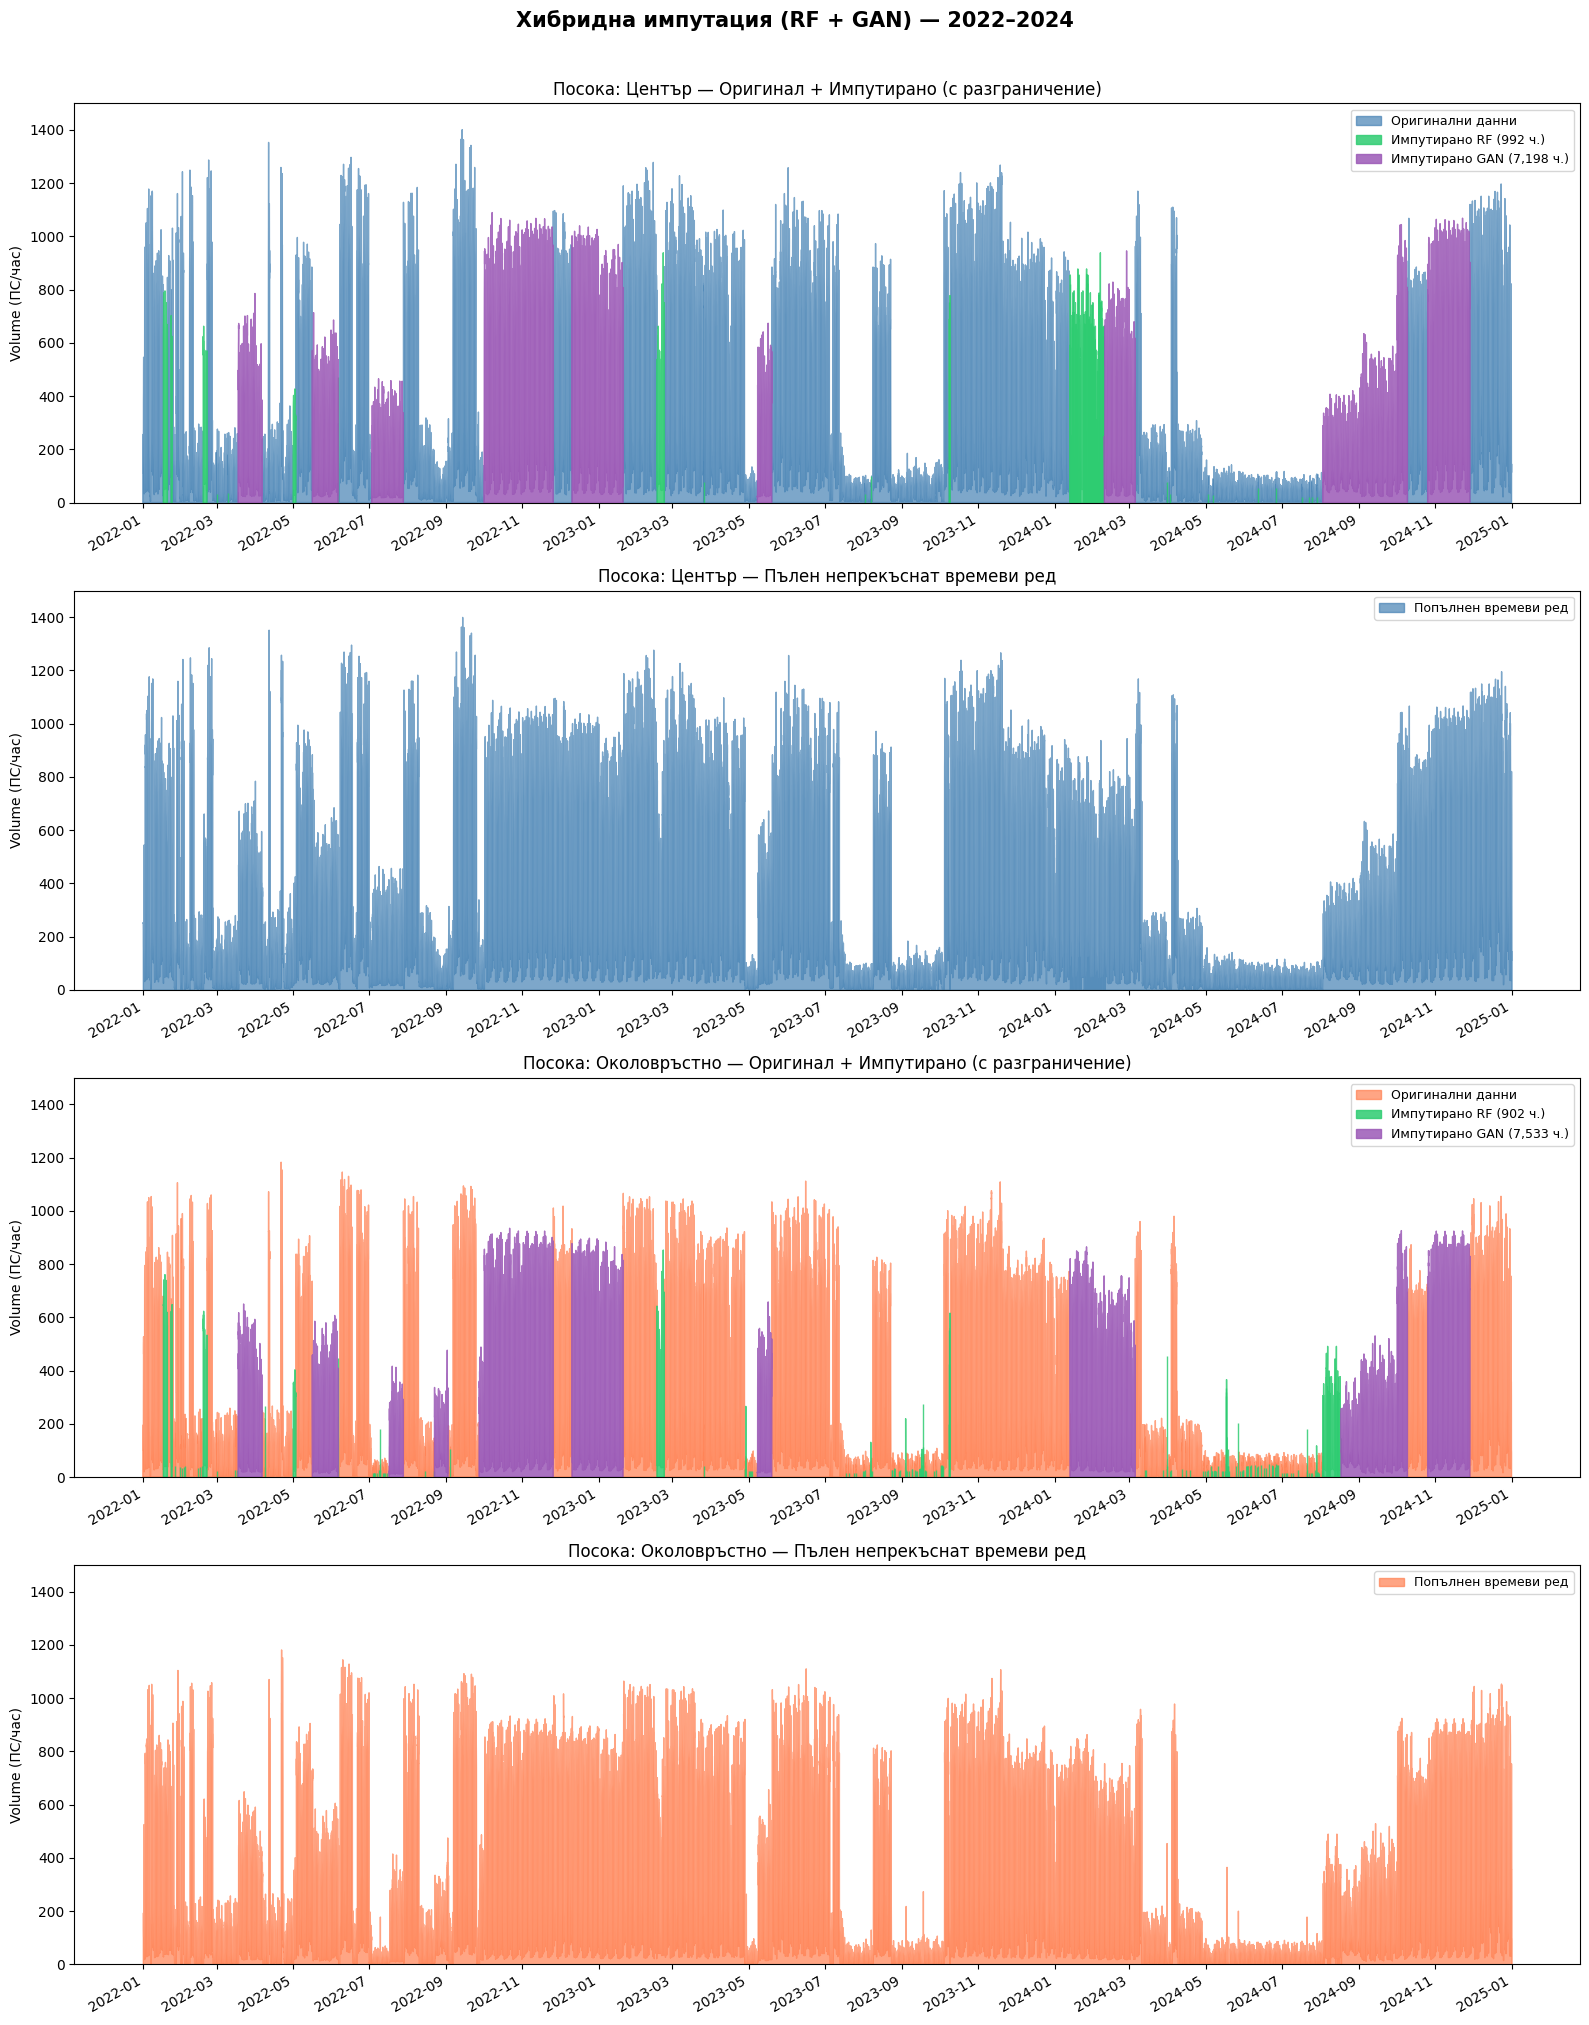


Запазено в data/traffic_imputed.csv
Редове : 52,608
Null   : 0


In [8]:
print("=" * 60)
print("ВИЗУАЛИЗАЦИЯ НА ПОПЪЛНЕНИЯ ВРЕМЕВИ РЕД")
print("=" * 60)

fig, axes = plt.subplots(4, 1, figsize=(16, 20))
fig.suptitle("Хибридна импутация (RF + GAN) — 2022–2024",
             fontsize=15, fontweight="bold", y=1.01)

directions = ["Център", "Околовръстно"]
colors     = {"Център": "steelblue", "Околовръстно": "coral"}
imp_colors = {"RF": "#2ecc71", "GAN": "#9b59b6"}

for i, direction in enumerate(directions):
    orig    = df[df["direction"] == direction].copy().reset_index(drop=True)
    imputed = df_imputed[df_imputed["direction"] == direction].copy().reset_index(drop=True)

    ax_top = axes[i*2]
    ax_bot = axes[i*2 + 1]

    # Серии само за импутираните стойности
    vol_rf   = imputed["volume"].where(imputed["imputation_method"] == "RF",  np.nan)
    vol_gan  = imputed["volume"].where(imputed["imputation_method"] == "GAN", np.nan)
    vol_orig = orig["volume"]  # с NaN в gap-овете

    rf_count  = imputed["imputation_method"].eq("RF").sum()
    gan_count = imputed["imputation_method"].eq("GAN").sum()

    # ГОРНА — оригинал + импутирани с различни цветове
    ax_top.fill_between(imputed["datetime"], vol_orig,
                        alpha=0.7, color=colors[direction],
                        label="Оригинални данни")
    ax_top.fill_between(imputed["datetime"], vol_rf,
                        alpha=0.85, color=imp_colors["RF"],
                        label=f"Импутирано RF ({rf_count:,} ч.)")
    ax_top.fill_between(imputed["datetime"], vol_gan,
                        alpha=0.85, color=imp_colors["GAN"],
                        label=f"Импутирано GAN ({gan_count:,} ч.)")
    ax_top.set_title(f"Посока: {direction} — Оригинал + Импутирано (с разграничение)",
                     fontsize=12)

    # ДОЛНА — само попълненият непрекъснат времеви ред
    ax_bot.fill_between(imputed["datetime"], imputed["volume"],
                        alpha=0.7, color=colors[direction],
                        label="Попълнен времеви ред")
    ax_bot.set_title(f"Посока: {direction} — Пълен непрекъснат времеви ред",
                     fontsize=12)

    for ax in [ax_top, ax_bot]:
        ax.set_ylabel("Volume (ПС/час)")
        ax.set_ylim(0, 1500)
        ax.legend(loc="upper right", fontsize=9)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.savefig("imputed_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

# Запазване на попълнения dataset
df_imputed.to_csv("data/traffic_imputed.csv", index=False)
print(f"\nЗапазено в data/traffic_imputed.csv")
print(f"Редове : {len(df_imputed):,}")
print(f"Null   : {df_imputed['volume'].isnull().sum():,}")

In [9]:
df_imputed.to_csv("data/traffic_imputed.csv", index=False)
print(f"Запазено в data/traffic_imputed.csv")
print(f"Редове             : {len(df_imputed):,}")
print(f"Null volume        : {df_imputed['volume'].isnull().sum():,}")
print(f"Импутирано с RF    : {(df_imputed['imputation_method']=='RF').sum():,}")
print(f"Импутирано с GAN   : {(df_imputed['imputation_method']=='GAN').sum():,}")
print(f"Оригинални данни   : {df_imputed['imputation_method'].isna().sum():,}")

Запазено в data/traffic_imputed.csv
Редове             : 52,608
Null volume        : 0
Импутирано с RF    : 1,894
Импутирано с GAN   : 14,731
Оригинални данни   : 35,983


In [10]:
print("=" * 60)
print("ФИНАЛНО ОБОБЩЕНИЕ")
print("=" * 60)

total = len(df_imputed) // 2  # часове (делено на 2 посоки)
orig  = 35983 // 2
rf    = 1894  // 2
gan   = 14731 // 2

print(f"Общо часове в периода    : {total:,}")
print(f"Оригинални часове        : {orig:,} ({orig/total*100:.1f}%)")
print(f"Импутирани с RF          : {rf:,}   ({rf/total*100:.1f}%)")
print(f"Импутирани с GAN         : {gan:,}  ({gan/total*100:.1f}%)")
print(f"\nПраг RF/GAN              : 168 часа (1 седмица)")
print(f"Финален dataset          : data/traffic_imputed.csv")
print(f"Null стойности           : 0")
print(f"\nМетодология:")
print(f"  Gap < 168 часа  → Random Forest (n_estimators=200, max_depth=10)")
print(f"  Gap ≥ 168 часа  → GAN (G=[256,128,64], D=[128,64], epochs=400)")

ФИНАЛНО ОБОБЩЕНИЕ
Общо часове в периода    : 26,304
Оригинални часове        : 17,991 (68.4%)
Импутирани с RF          : 947   (3.6%)
Импутирани с GAN         : 7,365  (28.0%)

Праг RF/GAN              : 168 часа (1 седмица)
Финален dataset          : data/traffic_imputed.csv
Null стойности           : 0

Методология:
  Gap < 168 часа  → Random Forest (n_estimators=200, max_depth=10)
  Gap ≥ 168 часа  → GAN (G=[256,128,64], D=[128,64], epochs=400)
